In [2]:
import seaborn
from scipy.special import softmax, log_softmax
from numpy.lib.stride_tricks import sliding_window_view
import scipy.stats as stats
import pickle
import json
from pathlib import Path
import warnings
import torch
import re
from collections import defaultdict
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import scipy
import numpy as np
from seaborn import kdeplot
from tqdm.auto import tqdm
from scipy.stats import gmean


def meanprob(answer_probabilities):
    return gmean([next(iter(value.values())) for value in answer_probabilities])

def sort_key(path):
    # To sort filepaths
    match = re.search(r'traj_(\d+)(?:_sample_(\d+))?', path.name)
    if match:
        traj_num = int(match.group(1))
        sample_num = int(match.group(2)) if match.group(2) is not None else -1
        return (traj_num, sample_num)
    return (float('inf'), float('inf'))

/pm/miniconda3/envs/users/han/cot/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


What to do:
1. I need histogram, ROC curve:
   - LLM
   - metric (meanprob, meanent, indirect1, verbal)
   - dataset
   - method (vanilla, real, bootstrap)
3. 2LLM*4 metrics =8 tables of AUC and timings of
   - method (vanilla, real, bootstrap) vs dataset

In [3]:
folder = Path("./trajectories/")

LLMS = ['llama', 'qwen']
DATASETS = ['movie_recommendation', 'math_500', 'causal_inference', 'logiqa', 'hotpotqa', 'bfcl', 'cs1qa', 'codeqa']
sample_filepaths = defaultdict(lambda: defaultdict(dict))

sample_filepaths['llama']['movie_recommendation']['real'] = folder/"1_full_trajectories/cots-420-llama-bm-32_llama_regular_bigbench_movie_zero_0_250_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['movie_recommendation']['real'] = folder/"1_full_trajectories/MERGED-cots-430-qwen-bm-8"
sample_filepaths['llama']['movie_recommendation']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-bm-504-llama_llama_regular_bigbench_movie_zero_0_250_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['movie_recommendation']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-bm-504-qwen_qwen_regular_bigbench_movie_zero_0_250_type1_conf_bootstrap_mod-none"

sample_filepaths['llama']['math_500']['real'] = folder/"1_full_trajectories/cots-420-llama-m500-32_llama_regular_math500_zero_0_498_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['math_500']['real'] = folder/"1_full_trajectories/MERGED-cots-502-qwen-m500-8"
sample_filepaths['llama']['math_500']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-m500-504-llama_llama_regular_math500_zero_0_498_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['math_500']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-math500-503-qwen_qwen_regular_math500_zero_0_498_type1_conf_bootstrap_mod-none"

sample_filepaths['llama']['causal_judgment']['real'] = folder/"1_full_trajectories/cots-420-llama-bc-32_llama_regular_bigbench_causal_zero_0_187_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['causal_judgment']['real'] = folder/"1_full_trajectories/MERGED-cots-501-qwen-bc-8"
sample_filepaths['llama']['causal_judgment']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-bc-504-llama_llama_regular_bigbench_causal_zero_0_187_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['causal_judgment']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-bc-503-qwen_qwen_regular_bigbench_causal_zero_0_187_type1_conf_bootstrap_mod-none"

sample_filepaths['llama']['logiqa']['real'] = folder/"1_full_trajectories/cots-420-llama-logiqa-32_llama_regular_logiqa_zero_0_500_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['logiqa']['real'] = folder/"1_full_trajectories/MERGED-cots-503-qwen-logiqa-8"
sample_filepaths['llama']['logiqa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-logiqa-504-llama_llama_regular_logiqa_zero_0_651_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['logiqa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-logiqa-505-qwen_qwen_regular_logiqa_zero_0_651_type2_conf_bootstrap_mod-none"

sample_filepaths['llama']['hotpotqa']['real'] = folder/"1_full_trajectories/cots-427-llama-hotpotqa-32_llama_regular_hotpotqa_zero_0_500_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['hotpotqa']['real'] = folder/"1_full_trajectories/MERGED-cots-503-qwen-hotpotqa-8"
sample_filepaths['llama']['hotpotqa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-hotpotqa-505-llama_llama_regular_hotpotqa_zero_0_7405_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['hotpotqa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-hotpotqa-505-qwen_qwen_regular_hotpotqa_zero_0_7405_type1_conf_bootstrap_mod-none"

sample_filepaths['llama']['bfcl']['real'] = folder/"1_full_trajectories/cots-420-llama-bfcl-32_llama_regular_bfcl_zero_0_500_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['bfcl']['real'] = folder/"1_full_trajectories/MERGED-cots-503-qwen-bfcl-8"
sample_filepaths['llama']['bfcl']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-bfcl-504-llama_llama_regular_bfcl_zero_0_1000_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['bfcl']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-bfcl-505-qwen_qwen_regular_bfcl_zero_0_1000_type1_conf_bootstrap_mod-none"

sample_filepaths['llama']['cs1qa']['real'] = folder/"1_full_trajectories/cots-427-llama-cs1qa_span-32_llama_regular_cs1qa_span_zero_0_500_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['cs1qa']['real'] = folder/"1_full_trajectories/MERGED-cots-503-qwen-cs1qa_span-8"
sample_filepaths['llama']['cs1qa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-cs1qa-span-505-llama_llama_regular_cs1qa_span_zero_0_989_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['cs1qa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-cs1qa-span-505-qwen_qwen_regular_cs1qa_span_zero_0_989_type1_conf_bootstrap_mod-none"

sample_filepaths['llama']['codeqa']['real'] = folder/"1_full_trajectories/cots-422-llama-codeqa-32_llama_regular_codeqa_zero_0_500_type2_conf_vanillaonly_mod-none_samples32"
sample_filepaths['qwen']['codeqa']['real'] = folder/"1_full_trajectories/MERGED-cots-503-qwen-codeqa-8"
sample_filepaths['llama']['codeqa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-codeqa-505-llama_llama_regular_codeqa_zero_0_35358_type2_conf_bootstrap_mod-none"
sample_filepaths['qwen']['codeqa']['true_bootstrap'] = folder/"1_true_bootstrap/bootstrap-codeqa-505-qwen_qwen_regular_codeqa_zero_0_35358_type1_conf_bootstrap_mod-none"

In [4]:
data = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(list))))

for llm in sample_filepaths:
    for dataset in sample_filepaths[llm]:
        for method in sample_filepaths[llm][dataset]:
            print(f"Loading {method} @ {dataset} @ {llm}")
            trajectories = []
            sample_files = sorted(sample_filepaths[llm][dataset][method].glob("traj_*.json"), key=sort_key)
            for sample_file in tqdm(sample_files):
                with open(sample_file, "r") as file:
                    trajectories += [json.load(file)]
            
            if method == 'real':
                resampled_confidences = None
            elif method == "true_bootstrap":
                resampled_confidences = 'bootstrap_confidences'
            else:
                raise Exception()
            
            for trajectory in tqdm(trajectories):
                traj_conf = trajectory['trajectory']['confidence_score']
                if traj_conf is not None:
                    data[llm][dataset][method]['answer_prompt'] += [trajectory['trajectory']['debug_info']['all_prompts']['answer_logits']]
                    data[llm][dataset][method]['indirect1_prompt'] += [trajectory['trajectory']['debug_info']['all_prompts']['indirect_ptrue1']]
                    data[llm][dataset][method]['verbal_prompt'] += [trajectory['trajectory']['debug_info']['all_prompts']['verbconf']]
                    data[llm][dataset][method]['raw_nb_steps'] += [len(trajectory['trajectory']['cot_steps'])]
                    data[llm][dataset][method]['id'] += [trajectory['trajectory']['id']]
                    data[llm][dataset][method]['answer_logits'] += [trajectory['trajectory']['debug_info']['answer_logits']]
                    # data[llm][dataset][method]['runtime'] += [trajectory['trajectory']['runtime_seconds']]
                    # if 'runtime_vanilla_seconds' in trajectory:
                    #     raise Exception()
                    #     data[llm][dataset][method]['vanilla_runtime'] += [trajectory['runtime_vanilla_seconds']]
                    # if 'timings' in traj_conf:
                    #     data[llm][dataset][method]['vanilla_forward_runtime'] += [np.mean([value for key, value in traj_conf['timings'].items() 
                    #                                                               if key.startswith('vanilla') and key.endswith('total_seconds')])]

                    if method == 'true_bootstrap':
                        # Llama
                        if llm=='llama':
                            # Vanilla
                            vanilla_confidence_cost = []
                            for measure in ['meanprob', 'meanent', 'indirect1', 'verbconf']:
                                vanilla_confidence_cost += [traj_conf['timings'][f'vanilla_{measure}_total_seconds']]
                            vanilla_single_conf = np.max(vanilla_confidence_cost)
                            vanilla_generation = trajectory['runtime_vanilla_seconds'] - vanilla_single_conf
                            vanilla_correction_factor = 0
                            vanilla_total_time = trajectory['runtime_vanilla_seconds'] + vanilla_correction_factor
                            
                            # Bootstrap
                            bootstrap_confidence_cost = []
                            for measure in ['meanprob', 'meanent', 'indirect1', 'verbconf']:
                                if f'bootstrap_{measure}_total_seconds' in traj_conf['timings']:
                                    bootstrap_confidence_cost += [traj_conf['timings'][f'bootstrap_{measure}_total_seconds']]
                            bootstrap_confidence_cost = np.max(bootstrap_confidence_cost)
                            bootstrap_total_time = vanilla_generation + bootstrap_confidence_cost
                        # Qwen
                        elif llm=='qwen':
                            # Vanilla
                            vanilla_confidence_cost = []
                            for measure in ['meanprob', 'meanent', 'indirect1', 'verbconf']:
                                vanilla_confidence_cost += [traj_conf['timings'][f'vanilla_{measure}_total_seconds']]
                            vanilla_generation = trajectory['runtime_vanilla_seconds'] - np.sum(vanilla_confidence_cost)
                            vanilla_single_conf = np.mean(vanilla_confidence_cost)
                            vanilla_correction_factor =  - np.sum(vanilla_confidence_cost) + vanilla_single_conf
                            vanilla_total_time = trajectory['runtime_vanilla_seconds'] + vanilla_correction_factor
                            
                            # Bootstrap
                            bootstrap_confidence_cost = []
                            for measure in ['meanprob', 'meanent', 'indirect1', 'verbconf']:
                                if f'bootstrap_{measure}_total_seconds' in traj_conf['timings']:
                                    bootstrap_confidence_cost += [traj_conf['timings'][f'bootstrap_{measure}_total_seconds']]
                            bootstrap_confidence_cost = np.max(bootstrap_confidence_cost)
                            bootstrap_total_time = vanilla_generation + bootstrap_confidence_cost

                        data[llm][dataset][method]['vanilla_runtime'] += [vanilla_total_time]
                        data[llm][dataset][method]['runtime'] += [bootstrap_total_time]
                        data[llm][dataset][method]['vanilla_runtime_correction'] += [vanilla_correction_factor]
                        data[llm][dataset][method]['1_bootstrap_forward_runtime'] += [bootstrap_confidence_cost]
                        data[llm][dataset][method]['1_vanilla_gen_runtime'] += [vanilla_generation]
                    elif method == 'real':
                        data[llm][dataset][method]['runtime'] += [trajectory['trajectory']['runtime_seconds']]
                    
                    accuracy = trajectory['trajectory']['correct']
                    
                    data[llm][dataset][method]['accuracy'] += [accuracy['em'] if isinstance(accuracy, dict) else accuracy]
                    data[llm][dataset][method]['correct_answer'] += [trajectory['trajectory']['ground_truth']]
                    data[llm][dataset][method]['cot_answer'] += [trajectory['trajectory']['final_answer']]
                    
                    data[llm][dataset][method]['vanilla_meanprob'] += [meanprob(traj_conf['vanilla_confidences']['answer_probabilities'])]
                    data[llm][dataset][method]['vanilla_meanent'] += [np.exp(-meanprob(traj_conf['vanilla_confidences']['answer_entropy']))]
                    data[llm][dataset][method]['vanilla_indirect'] += [traj_conf['vanilla_confidences']['indirect_ptrue1_probabilities'][0]['True']]
                    data[llm][dataset][method]['vanilla_verbal'] += [traj_conf['vanilla_confidences']['verbconf_probabilities'][0]]

                    if resampled_confidences is not None:
                        if len(traj_conf[resampled_confidences]['answer_probabilities'])==0:
                            traj_conf[resampled_confidences]['step_masks'] = [[1] for _ in range(100)]
                            for key in ['answer_probabilities', 'answer_entropy']:
                                traj_conf[resampled_confidences][key] = [traj_conf['vanilla_confidences'][key] for _ in range(100)]
                            for key in ['indirect_ptrue1_probabilities', 'indirect_ptrue2_probabilities', 'verbconf_probabilities']:
                                traj_conf[resampled_confidences][key] = [traj_conf['vanilla_confidences'][key][0] for _ in range(100)]
                        mask = traj_conf[resampled_confidences]['step_masks']
                        if mask:
                            data[llm][dataset][method]['mask'] += [torch.LongTensor(mask)]
                            data[llm][dataset][method]['nb_steps'] += [torch.LongTensor(mask).sum(-1).tolist()]
                            _, first_occurrences = np.unique(mask, axis=0, return_index=True)
                        data[llm][dataset][method]['resampled_meanprob'] += [[meanprob(confidence) for confidence in traj_conf[resampled_confidences]['answer_probabilities']]]
                        data[llm][dataset][method]['resampled_meanent'] += [[np.exp(-meanprob(confidence)) for confidence in traj_conf[resampled_confidences]['answer_entropy']]]
                        data[llm][dataset][method]['resampled_indirect'] += [[confidence['True'] for confidence in traj_conf[resampled_confidences]['indirect_ptrue1_probabilities']]]
                        data[llm][dataset][method]['resampled_verbal'] += [traj_conf[resampled_confidences]['verbconf_probabilities']]
                        data[llm][dataset][method]['first_occurrences'] += [sorted(first_occurrences.tolist())]
            
            data[llm][dataset][method]['accuracy'] = torch.BoolTensor(data[llm][dataset][method]['accuracy'])
            data[llm][dataset][method]['raw_nb_steps'] = torch.LongTensor(data[llm][dataset][method]['raw_nb_steps'])
            if resampled_confidences is not None:
                data[llm][dataset][method]['nb_steps'] = torch.LongTensor(data[llm][dataset][method]['nb_steps'])
            for key in data[llm][dataset][method]:
                if key.startswith('vanilla_') or key.startswith('resampled_'): 
                    data[llm][dataset][method][key] = torch.FloatTensor(data[llm][dataset][method][key])

Loading real @ movie_recommendation @ llama


100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 8000/8000 [00:02<00:00, 3276.56it/s]


Loading true_bootstrap @ movie_recommendation @ llama


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 250/250 [00:07<00:00, 33.88it/s]


Loading real @ math_500 @ llama


...

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:14<00:00, 33.44it/s]


Loading real @ codeqa @ qwen


100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 4000/4000 [00:01<00:00, 3600.02it/s]


Loading true_bootstrap @ codeqa @ qwen


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:13<00:00, 36.06it/s]


In [ ]:
data.keys()


In [5]:
# from scipy.stats.mstats import mquantiles

def rescale(x):
    # return x
    return x.logit().clip(-5,5)


vanilla_dist_type = 'true_bootstrap'
accuracies = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(list))))
rescaled_confidences = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(list))))
test_statistics = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(list))))
timings = defaultdict(lambda: defaultdict(lambda: defaultdict(lambda: defaultdict(list))))
for llm in data:
    for dataset in data[llm]:
        nb_samples = len(data[llm][dataset][vanilla_dist_type]['id'])
        for metric in ['meanprob', 'meanent', 'indirect', 'verbal']:
            for sample_id in tqdm(range(nb_samples)):
                rescaled_confidence = {}
                total_timing = {}
                
                # Vanilla
                id_ = data[llm][dataset][vanilla_dist_type]['id'][sample_id]
                cot_answer = data[llm][dataset][vanilla_dist_type]['cot_answer'][sample_id]
                accuracy = data[llm][dataset][vanilla_dist_type]['accuracy'][sample_id]
                rescaled_confidence['vanilla'] = rescale(data[llm][dataset][vanilla_dist_type]['vanilla_'+metric][sample_id].unsqueeze(0))
                total_timing['vanilla'] = data[llm][dataset][vanilla_dist_type]['vanilla_runtime'][sample_id]
                
                # True bootstrap
                assert data[llm][dataset]['true_bootstrap']['id'][sample_id] == id_
                assert data[llm][dataset]['true_bootstrap']['cot_answer'][sample_id] == cot_answer
                includes_last_step = data[llm][dataset]['true_bootstrap']['mask'][sample_id][:,-1].bool()
                assert includes_last_step.all()
                rescaled_confidence['true_bootstrap_100'] = rescale(data[llm][dataset]['true_bootstrap']['resampled_'+metric][sample_id])
                total_timing['true_bootstrap_100'] = data[llm][dataset]['true_bootstrap']['runtime'][sample_id]
                rescaled_confidence['true_bootstrap_10'] = rescale(data[llm][dataset]['true_bootstrap']['resampled_'+metric][sample_id])[:10]
                total_timing['true_bootstrap_10'] = data[llm][dataset]['true_bootstrap']['1_vanilla_gen_runtime'][sample_id]\
                                                            +(10/100)*data[llm][dataset]['true_bootstrap']['1_bootstrap_forward_runtime'][sample_id]
                
                # Real
                friends = ((np.array(data[llm][dataset]['real']['id'])==id_)\
                        &(np.array(data[llm][dataset]['real']['cot_answer'])==cot_answer)).nonzero()[0]
                rescaled_confidence['real'] = rescale(data[llm][dataset]['real']['vanilla_'+metric][friends])
                same_id = (np.array(data[llm][dataset]['real']['id'])==id_)
                total_timing['real'] = torch.FloatTensor(data[llm][dataset]['real']['runtime']
                                                         +data[llm][dataset]['real']['vanilla_runtime_correction'])[same_id].sum()
                
                if len(friends)>1:
                    for method in rescaled_confidence:
                        accuracies[llm][dataset][metric][method] += [accuracy]
                        rescaled_confidences[llm][dataset][metric][method] += [rescaled_confidence[method]]
                        test_statistics[llm][dataset][metric][method] += [torch.mean(rescaled_confidence[method])]
                        timings[llm][dataset][metric][method] += [total_timing[method]/total_timing['vanilla']]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 499/499 [00:01<00:00, 291.90it/s]


In [ ]:
timings


# 1a. Histograms

# 1c. ROC Curves

In [13]:
COLORS = {
    "vanilla": "2F4858",
    "true_bootstrap_10": "336699",
    "true_bootstrap_100": "86BBD8",
    "real": "9EE493"
}

LABELS = {
    'movie_recommendation': 'MovieRec',
    'math_500': 'Math500', 
    'causal_judgment': 'Causal', 
    'logiqa': 'LogiQA', 
    'hotpotqa': 'HotPotQA',
    'bfcl': 'BFCL',
    'cs1qa': 'CS1QA',
    'codeqa': 'CodeQA',
    'vanilla': 'Vanilla',
    'true_bootstrap_10': 'StepBootstrap (10)',
    'true_bootstrap_100': 'StepBootstrap (100)',
    'real': 'Ideal',
    'llama': 'Llama 3.1 8B',
    'qwen': "Qwen 3.5 27B",
    'meanprob': 'Answer token perplexity',
    'meanent': 'Answer token entrophy',
    'indirect': 'Indirect logit',
    'verbal': 'Verbalized confidence'
}

In [19]:
plt.rcParams['text.usetex'] = False

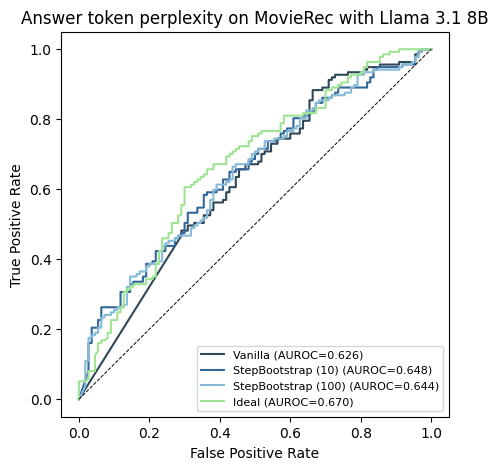

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score

def plot_roc_methods(llm, dataset, metric, ax=None, save_dir=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))
    else:
        fig = ax.figure
    for method in ['vanilla', 'true_bootstrap_10', 'true_bootstrap_100', 'real']:
        y = np.array(accuracies[llm][dataset][metric][method])
        s = np.array(test_statistics[llm][dataset][metric][method])
        if len(np.unique(y)) < 2:
            continue
        fpr, tpr, _ = roc_curve(y, s)
        auroc = roc_auc_score(y, s)
        ax.plot(fpr, tpr, color='#' + COLORS[method], label=f'{LABELS[method]} (AUROC={auroc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=0.7)
    ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title=f'{LABELS[metric]} on {LABELS[dataset]} with {LABELS[llm]}')
    ax.legend(loc='lower right', fontsize=8)
    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_dir / f"roc_{llm}_{dataset}_{metric}.pdf", bbox_inches='tight')
    return ax

plot_roc_methods('llama', 'movie_recommendation', 'meanprob')
plt.show()

In [ ]:
metrics = ['meanprob', 'meanent', 'indirect', 'verbal']
llms = ['llama', 'qwen']
datasets = ['movie_recommendation', 'math_500', 'causal_judgment', 'logiqa', 'hotpotqa', 'bfcl', 'cs1qa', 'codeqa']
out_dir = Path("figures_roc")

In [ ]:
for llm in llms:
    for dataset in datasets:
        for metric in metrics:
            fig, ax = plt.subplots(figsize=(5,5))
            plot_roc_methods(llm, dataset, metric, ax=ax, save_dir = out_dir)
            plt.close(fig)

# 2. OTHERS - Han : Statistical significance testing

In [66]:
from sklearn.metrics import roc_auc_score as auroc
from itertools import product                                                                                                                                                     
from tqdm.auto import tqdm

In [117]:
llms = ['llama', 'qwen']
metrics = ['meanprob', 'meanent', 'indirect', 'verbal']
methods = ['vanilla', 'true_bootstrap_100', 'true_bootstrap_10', 'real']
datasets = ['movie_recommendation', 'math_500', 'causal_judgment', 'logiqa', 'hotpotqa', 'bfcl', 'cs1qa', 'codeqa']

In [132]:
test_statistics['qwen']['cs1qa']['verbal']


defaultdict(list,
            {'vanilla': [tensor(-0.1669),
              tensor(-0.2227),
              tensor(-0.2006),
              tensor(-0.1252),
              tensor(-0.2031),
              tensor(-0.3506),
              tensor(-0.1574),
              tensor(-0.2807),
              tensor(-0.2512),
              tensor(-0.2614),
              tensor(-0.2290),
              tensor(-0.2633),
              tensor(-0.2169),
              tensor(-0.2500),
              tensor(-0.2225),
              tensor(-0.6129),
              tensor(-0.3897),
              tensor(-0.2737),
              tensor(-0.2839),
              tensor(-0.1934),
              tensor(-0.1976),
              tensor(-0.3259),
              tensor(-0.2302),
              tensor(-0.2518),
              tensor(-0.1385),
              tensor(-0.2414),
              tensor(-0.1756),
              tensor(-0.1331),
              tensor(-0.3830),
              tensor(-0.2614),
              tensor(-0.1325),
          

In [137]:
timings['qwen']['bfcl']['verbal']['vanilla']

[tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),
 tensor(1.),

In [139]:
# original_auroc = auroc(test_statistics['true_bootstrap'], accuracy_labels)

#  Plus Minus

original_aurocs = defaultdict(lambda: defaultdict(dict))
std_aurocs = defaultdict(lambda: defaultdict(dict))

combos = list(product(llms, datasets, metrics))
for llm in llms:
    for dataset in datasets:


        for metric in metrics:

            confs = {m: np.array(test_statistics[llm][dataset][metric][m]) for m in methods}                                                                                      
            accs = np.array(accuracies[llm][dataset][metric][methods[0]])  # same across methods                                                                                  
                                                                                                                                                                                
            original = {m: auroc(accs, confs[m]) for m in methods}

            aurocs = defaultdict(list)
            sub_std_aurocs = defaultdict(list)
            n = len(accs)                                                                                                                   
            for _ in range(1000):                                                                                                                                                 
                I = np.random.choice(n, size=n, replace=True)                                                                                                                     
                for m in methods:                                                                                                                                                 
                    aurocs[m].append(auroc(accs[I], confs[m][I]))
            for m in methods:
                sub_std_aurocs[m] = np.std(aurocs[m])
                print(f"{llm}_{dataset}_{metric}_{m}: {original[m]:.4f} ± {sub_std_aurocs[m]:.4f}")

            # is_significant = np.mean(aurocs['true_bootstrap'] > aurocs['vanilla']) > 0.95
            # if is_significant:
            #     print(f"{llm}_{dataset}_{metric} is significant")

            std_aurocs[llm][dataset][metric] = sub_std_aurocs
            original_aurocs[llm][dataset][metric] = original



            
            # for method in methods:
            #     accuracy_labels = accuracies[llm][dataset][metric][method]
            #     original_auroc = auroc(accuracy_labels, test_statistics[llm][dataset][metric][method])
            #     aurocs = []
            #     for _ in range(1000):
            #         I = np.random.choice(len(accuracy_labels), size = len(accuracy_labels), replace=True)
            #         aurocs += [auroc(test_statistics[llm][dataset][metric][method][I], accuracy_labels[I])]
                
            #     print(f"{llm}_{dataset}_{metric}_{method}: {original_auroc} ± {np.std(aurocs)}")

llama_movie_recommendation_meanprob_vanilla: 0.6261 ± 0.0349
llama_movie_recommendation_meanprob_true_bootstrap_100: 0.6442 ± 0.0354
llama_movie_recommendation_meanprob_true_bootstrap_10: 0.6481 ± 0.0350
llama_movie_recommendation_meanprob_real: 0.6696 ± 0.0346
llama_movie_recommendation_meanent_vanilla: 0.6342 ± 0.0360
llama_movie_recommendation_meanent_true_bootstrap_100: 0.6531 ± 0.0351
llama_movie_recommendation_meanent_true_bootstrap_10: 0.6516 ± 0.0347
llama_movie_recommendation_meanent_real: 0.6861 ± 0.0337
llama_movie_recommendation_indirect_vanilla: 0.5637 ± 0.0369
llama_movie_recommendation_indirect_true_bootstrap_100: 0.5674 ± 0.0365
llama_movie_recommendation_indirect_true_bootstrap_10: 0.5630 ± 0.0367
llama_movie_recommendation_indirect_real: 0.5938 ± 0.0361
llama_movie_recommendation_verbal_vanilla: 0.7772 ± 0.0291
llama_movie_recommendation_verbal_true_bootstrap_100: 0.7973 ± 0.0281
llama_movie_recommendation_verbal_true_bootstrap_10: 0.7950 ± 0.0281
llama_movie_recommen

In [122]:
# Std for timings
# original_aurocs = defaultdict(lambda: defaultdict(dict))
std_timings = defaultdict(lambda: defaultdict(dict))


for llm in llms:
    for dataset in datasets:

        for metric in metrics:

            times = {m: np.array(timings[llm][dataset][metric][m]) for m in methods}

            n = len(times[methods[0]])
            bootstrap_timings = defaultdict(list)                                                                                                                   
            for _ in range(1000):                                                                                                                                                 
                I = np.random.choice(n, size=n, replace=True)                                                                                                                     
                for m in methods:                                                                                                                                                 
                    bootstrap_timings[m].append(np.mean(times[m][I]))

            std_timings[llm][dataset][metric] = {m : np.std(bootstrap_timings[m]) for m in methods}

            

In [125]:
# std_timings['llama']['movie_recommendation']['indirect'].keys()
std_aurocs['llama']['movie_recommendation']['indirect'].keys()

dict_keys(['vanilla', 'true_bootstrap_100', 'true_bootstrap_10', 'real'])

In [126]:
# [model, dataset, metric]
averaged_std_aurocs = defaultdict(lambda: defaultdict(dict))
averaged_std_timings = defaultdict(lambda: defaultdict(dict))

for model in llms:
    print(f"Doing {model} right now")
    for dataset in tqdm(datasets):
        vanilla_cumulative = 0.0
        bootstrap_100_cumulative = 0.0
        bootstrap_10_cumulative = 0.0
        real_cumulative = 0.0
        timings_vanilla_cumulative = 0.0
        timings_bootstrap_100_cumulative = 0.0
        timings_bootstrap_10_cumulative = 0.0
        timings_real_cumulative = 0.0
        for metric in metrics:
            vanilla_cumulative += std_aurocs[model][dataset][metric]['vanilla']
            bootstrap_100_cumulative += std_aurocs[model][dataset][metric]['true_bootstrap_100']
            bootstrap_10_cumulative += std_aurocs[model][dataset][metric]['true_bootstrap_10']
            real_cumulative += std_aurocs[model][dataset][metric]['real']
            timings_vanilla_cumulative += std_timings[model][dataset][metric]['vanilla']
            timings_bootstrap_100_cumulative += std_timings[model][dataset][metric]['true_bootstrap_100']
            timings_bootstrap_10_cumulative += std_timings[model][dataset][metric]['true_bootstrap_10']
            timings_real_cumulative += std_timings[model][dataset][metric]['real']
        averaged_std_aurocs[model][dataset]['vanilla'] = vanilla_cumulative / 4.0
        averaged_std_aurocs[model][dataset]['true_bootstrap_100'] = bootstrap_100_cumulative / 4.0
        averaged_std_aurocs[model][dataset]['true_bootstrap_10'] = bootstrap_10_cumulative / 4.0
        averaged_std_aurocs[model][dataset]['real'] = real_cumulative / 4.0
        averaged_std_timings[model][dataset]['vanilla'] = timings_vanilla_cumulative / 4.0
        averaged_std_timings[model][dataset]['true_bootstrap_100'] = timings_bootstrap_100_cumulative / 4.0
        averaged_std_timings[model][dataset]['true_bootstrap_10'] = timings_bootstrap_10_cumulative / 4.0
        averaged_std_timings[model][dataset]['real'] = timings_real_cumulative / 4.0
        




Doing llama right now


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 41579.22it/s]


Doing qwen right now


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 52428.80it/s]


In [127]:
averaged_std_timings['llama']['math_500']['real']

np.float32(27.513506)

In [128]:
def generate_results_table_with_std(
    test_statistics, 
    accuracies, 
    timings, 
    averaged_std_aurocs,
    averaged_std_timings,
    dataset_labels, 
    method_labels, 
    llm_labels,
    output_filename="results_table.tex"
):
    """
    Computes AUROC and average timings, aggregates over metrics,
    maps names to labels in the provided order, and prints/saves
    a formatted LaTeX table matching the exact tabular rules template.
    """
    
    # 1, 2, & 3: Compute and Average the AUROCs and Timings over metrics
    processed_results = {}
    
    for llm in test_statistics:
        processed_results[llm] = {}
        for dataset in test_statistics[llm]:
            processed_results[llm][dataset] = {}
            
            # Find all unique methods across metrics for the dataset
            try:
                first_metric = list(test_statistics[llm][dataset].keys())[0]
                methods = list(test_statistics[llm][dataset][first_metric].keys())
            except Exception:
                print(f"{llm}-{dataset}")
                raise
            
                
            for method in methods:
                auroc_list = []
                timing_list = []
                
                for metric in test_statistics[llm][dataset]:
                    conf = test_statistics[llm][dataset][metric][method]
                    acc = accuracies[llm][dataset][metric][method]
                    time_val = timings[llm][dataset][metric][method]
                    
                    # Convert inputs to NumPy arrays
                    conf_arr = np.array(conf)
                    acc_arr = np.array(acc)
                    
                    # Compute AUROC only if valid (more than one class present)
                    if len(np.unique(acc_arr)) > 1:
                        try:
                            auroc_val = roc_auc_score(acc_arr, conf_arr)
                            auroc_list.append(auroc_val)
                        except ValueError:
                            pass
                    elif len(np.unique(acc_arr)) == 1:
                        auroc_list.append(1.0 if acc_arr[0] == 1 else 0.0)
                    
                    # Timing aggregation
                    timing_list.append(time_val)
                
                # Average metrics for this method in this dataset
                mean_auroc = np.mean(auroc_list) if auroc_list else 0.0
                mean_timing = np.mean(timing_list) if timing_list else 0.0

                std = float(averaged_std_aurocs[llm][dataset][method])
                std_timing = float(averaged_std_timings[llm][dataset][method])
                
                processed_results[llm][dataset][method] = (mean_auroc, std, mean_timing, std_timing)

    # 4. Construct the LaTeX code
    latex_lines = []
    latex_lines.append(r"\begin{table}[t]")
    latex_lines.append(r"    \caption{Main results.}")
    latex_lines.append(r"    \label{tab:main-results}")
    
    # Identify ordered datasets and methods from dictionary keys
    ordered_datasets = [d for d in dataset_labels.keys() if any(d in processed_results[llm] for llm in processed_results)]
    ordered_methods = [m for m in method_labels.keys()]
    
    # Iterate through each LLM (in the order provided by llm_labels)
    ordered_llms = [l for l in llm_labels.keys() if l in processed_results]
    
    for l_idx, llm in enumerate(ordered_llms):
        # Insert space between distinct LLM sections
        if l_idx > 0:
            latex_lines.append("\n")
            latex_lines.append(r"    \vspace{10pt}")
        
        llm_display_name = llm_labels.get(llm, llm)
        
        # Filter datasets available for the current LLM matching the ordered dictionary
        llm_datasets = [d for d in ordered_datasets if d in processed_results[llm]]
        
        # Group datasets into chunks of up to 4
        chunk_size = 4
        dataset_chunks = [llm_datasets[i:i + chunk_size] for i in range(0, len(llm_datasets), chunk_size)]
        
        for c_idx, chunk in enumerate(dataset_chunks):
            if c_idx > 0:
                latex_lines.append(r"    \vspace{5pt}")
            
            num_cols = len(chunk)
            total_tabular_cols = 1 + (2 * num_cols)
            tabular_spec = "l" + "c" * (2 * num_cols)
            
            latex_lines.append(f"    \\begin{{tabular}}{{{tabular_spec}}}")
            
            # Top rule and Title Row ONLY for the first chunk of this LLM
            if c_idx == 0:
                latex_lines.append(r"        \toprule")
                latex_lines.append(f"        \\multicolumn{{{total_tabular_cols}}}{{c}}{{\\textbf{{{llm_display_name}}}}} \\\\")
                latex_lines.append(r"        \vspace{-5pt}\\")
            
            # Header Row 1: Dataset custom labels
            header_1 = [r"        \multirow{2}{*}{}"]
            for d in chunk:
                label = dataset_labels.get(d, d)
                header_1.append(f"\\multicolumn{{2}}{{c}}{{\\textsc{{{label}}}}}")
            latex_lines.append(" & ".join(header_1) + r" \\")
            
            # Midrules
            midrules = []
            for i in range(num_cols):
                start = 2 + i * 2
                end = start + 1
                midrules.append(f"\\cmidrule(lr){{{start}-{end}}}")
            latex_lines.append("        " + " ".join(midrules))
            
            # Header Row 2: Metrics
            header_2 = ["         "]
            for _ in chunk:
                header_2.extend(["AUROC", "Timing"])
            latex_lines.append(" & ".join(header_2) + r" \\")
            
            # Repeated Midrules below the Metric header row
            latex_lines.append("        " + " ".join(midrules))
            
            # Rows: Methods (in the exact order of the labels dict)
            for m in ordered_methods:
                method_display_name = method_labels.get(m, m)
                row = [f"        {method_display_name}"]
                for d in chunk:
                    if m in processed_results[llm][d]:
                        auroc, std, timing, std_timing = processed_results[llm][d][m]
                        row.append(f"{auroc:.4f} $\\pm$ {std:.4f}")
                        row.append(f"{timing:2.3f}s $\\pm$ {std_timing:2.3f}")
                    else:
                        row.append("-")
                        row.append("-")
                latex_lines.append(" & ".join(row) + r" \\")
            
            # Bottom rule ONLY for the last chunk of this LLM
            if c_idx == len(dataset_chunks) - 1:
                latex_lines.append(r"        \bottomrule")
                
            latex_lines.append(r"    \end{tabular}")
            
    latex_lines.append(r"\end{table}")
    
    latex_code = "\n".join(latex_lines)
    
    # Print to console
    print(latex_code)
    
    # Save to file
    with open(output_filename, "w", encoding="utf-8") as f:
        f.write(latex_code)
        
    print(f"\nLaTeX table successfully written to {output_filename}")

    return latex_code

In [130]:
generate_results_table_with_std(
    test_statistics, 
    accuracies, 
    timings,
    averaged_std_aurocs=averaged_std_aurocs,
    averaged_std_timings=averaged_std_timings,
    dataset_labels={'movie_recommendation': 'MovieRec',
                    'math_500': 'Math500', 
                    'causal_judgment': 'Causal', 
                    'logiqa': 'LogiQA', 
                    'hotpotqa': 'HotPotQA',
                    'bfcl': 'BFCL',
                    'cs1qa': 'CS1QA',
                    'codeqa': 'CodeQA',
                   },
    method_labels={'vanilla': 'Vanilla', 
                   # 'bootstrap_q25': 'StepBootstrap (25th quantile)',
                   'true_bootstrap_10': 'StepBootstrap (10)',
                   'true_bootstrap_100': 'StepBootstrap (100)',
                   # 'bootstrap_q75': 'StepBootstrap (75th quantile)',
                   # 'real_q25': 'Ideal (25th quantile)',
                   'real': 'Ideal',
                   # 'real_q75': 'Ideal (75th quantile)',
                  }, 
    llm_labels={'llama': 'Llama 3.1 8B',
                'qwen': 'Qwen 3.5 27B'},
    output_filename="main_table.tex")

\begin{table}[t]
    \caption{Main results.}
    \label{tab:main-results}
    \begin{tabular}{lcccccccc}
        \toprule
        \multicolumn{9}{c}{\textbf{Llama 3.1 8B}} \\
        \vspace{-5pt}\\
        \multirow{2}{*}{} & \multicolumn{2}{c}{\textsc{MovieRec}} & \multicolumn{2}{c}{\textsc{Math500}} & \multicolumn{2}{c}{\textsc{Causal}} & \multicolumn{2}{c}{\textsc{LogiQA}} \\
        \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7} \cmidrule(lr){8-9}
          & AUROC & Timing & AUROC & Timing & AUROC & Timing & AUROC & Timing \\
        \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7} \cmidrule(lr){8-9}
        Vanilla & 0.6503 $\pm$ 0.0334 & 7.849s $\pm$ 0.054 & 0.6509 $\pm$ 0.0287 & 15.147s $\pm$ 1.690 & 0.5315 $\pm$ 0.0438 & 6.910s $\pm$ 0.061 & 0.5536 $\pm$ 0.0256 & 9.219s $\pm$ 0.592 \\
        StepBootstrap (10) & 0.6644 $\pm$ 0.0325 & 8.100s $\pm$ 0.054 & 0.6476 $\pm$ 0.0285 & 15.554s $\pm$ 1.733 & 0.5395 $\pm$ 0.0434 & 7.172s $\pm$ 0.062 & 0.5698 $\pm$ 0.02

'\\begin{table}[t]\n    \\caption{Main results.}\n    \\label{tab:main-results}\n    \\begin{tabular}{lcccccccc}\n        \\toprule\n        \\multicolumn{9}{c}{\\textbf{Llama 3.1 8B}} \\\\\n        \\vspace{-5pt}\\\\\n        \\multirow{2}{*}{} & \\multicolumn{2}{c}{\\textsc{MovieRec}} & \\multicolumn{2}{c}{\\textsc{Math500}} & \\multicolumn{2}{c}{\\textsc{Causal}} & \\multicolumn{2}{c}{\\textsc{LogiQA}} \\\\\n        \\cmidrule(lr){2-3} \\cmidrule(lr){4-5} \\cmidrule(lr){6-7} \\cmidrule(lr){8-9}\n          & AUROC & Timing & AUROC & Timing & AUROC & Timing & AUROC & Timing \\\\\n        \\cmidrule(lr){2-3} \\cmidrule(lr){4-5} \\cmidrule(lr){6-7} \\cmidrule(lr){8-9}\n        Vanilla & 0.6503 $\\pm$ 0.0334 & 7.849s $\\pm$ 0.054 & 0.6509 $\\pm$ 0.0287 & 15.147s $\\pm$ 1.690 & 0.5315 $\\pm$ 0.0438 & 6.910s $\\pm$ 0.061 & 0.5536 $\\pm$ 0.0256 & 9.219s $\\pm$ 0.592 \\\\\n        StepBootstrap (10) & 0.6644 $\\pm$ 0.0325 & 8.100s $\\pm$ 0.054 & 0.6476 $\\pm$ 0.0285 & 15.554s $\\pm$ 1.733 & 

In [84]:
del test_statistics['llama']['qwen'] 

In [27]:
# #  Plus Minus: moving sampling I outside of metric for loop

# original_aurocs = defaultdict(lambda: defaultdict(dict))
# std_aurocs = defaultdict(lambda: defaultdict(dict))

# combos = list(product(llms, datasets, metrics))
# for llm in llms:
#     for dataset in tqdm(datasets):

#         confs = {metric: {m: np.array(test_statistics[llm][dataset][metric][m]) for m in methods} for metric in metrics}
#         accs = {metric: np.array(accuracies[llm][dataset][metric][methods[0]]) for metric in metrics}

#         original = {metric: {m: auroc(accs[metric], confs[metric][m]) for m in methods} for metric in metrics}
#         # length of accuracy labels are of the same length per dataset
#         n = len(accs[metrics[0]])

#         # aurocs[metric][method]
#         aurocs = defaultdict(lambda: defaultdict(list))
#         for _ in range(1000):
#             I = np.random.choice(n, size=n, replace=True)

#             # the 4 metrics
#             for metric in metrics:
#                 accs_I = accs[metric][I]
#                 for m in methods:
#                     aurocs[metric][m].append(auroc(accs_I, confs[metric][m]))


#         for metric in metrics:
#             sub_std = {m: np.std(aurocs[metric][m]) for m in methods}

#             for m in methods:
#                 print(f"{llm}_{dataset}_{metric}_{m}: {original[metric][m]:.4f} ± {sub_std[m]:.4f}"
#             std_aurocs[llm][dataset][metric] = sub_std
#             original_aurocs[llm][dataset][metric] = original[metric]
                
                
#                 # sub_std_aurocs = defaultdict(list)
#                 # # n = len(accs)                                                                                                                   
#                 # # for _ in range(1000):                                                                                                                                                 
#                 # #     I = np.random.choice(n, size=n, replace=True)                                                                                                                     
#                 # for m in methods:                                                                                                                                                 
#                 #     aurocs[m].append(auroc(accs[I], confs[m][I]))
#                 # for m in methods:
#                 #     sub_std_aurocs[m] = np.std(aurocs[m])
#                 #     print(f"{llm}_{dataset}_{metric}_{m}: {original[m]:.4f} ± {sub_std_aurocs[m]:.4f}")
        
        
#                 # std_aurocs[llm][dataset][metric] = sub_std_aurocs
#                 # original_aurocs[llm][dataset][metric] = original


SyntaxError: '(' was never closed (976796841.py, line 33)

In [ ]:
std_aurocs

# 6. Abandoned 

In [ ]:
# original_auroc = auroc(mean_confidences['true_bootstrap'], accuracy_labels)

# aurocs = defaultdict(list)
# for _ in range(1000):
#     I = np.random.choice(len(accuracy_labels), size = len(accuracy_labels), replace=True)
#     aurocs['true_bootstrap'] += [auroc(mean_confidence['true_bootstrap'][I], accuracy_labels[I])]
#     aurocs['vanilla'] += [auroc(mean_confidence['vanilla'][I], accuracy_labels[I])]
# for key in aurocs:
#     aurocs[key] = np.array(aurocs[key])

# is_significant = np.mean(aurocs['true_bootstrap'] > aurocs['vanilla']) > 0.95
# print(f"{original_aurocs} +- {np.std(aurocs)}")

## 6.1. Histograms and prev roc curve

In [ ]:
# llm = 'llama'
# dataset = 'movie_recommendation'

# # 1. Initialize two separate figures with a 2x2 grid
# # Using a square-ish figsize (e.g., 12x10) works well for 2x2 grids
# fig_left, axes_left = plt.subplots(2, 2, figsize=(8, 6))
# fig_right, axes_right = plt.subplots(2, 2, figsize=(8, 6))

# # Flatten the 2D arrays (2,2) into 1D arrays of length 4 for easy looping
# axes_left_flat = axes_left.flatten()
# axes_right_flat = axes_right.flatten()

# for i, metric in enumerate(rescaled_confidences[llm][dataset]):
#     # Ensure we don't go out of bounds if there are more than 4 metrics
#     if i >= 4: break 
    
#     # --- LEFT HAND SIDE PLOTS (Logits) ---
#     ax_l = axes_left_flat[i]
#     real_diff = torch.cat([t-vanilla for t, vanilla in zip(rescaled_confidences[llm][dataset][metric]['real'], 
#                                                            rescaled_confidences[llm][dataset][metric]['vanilla'])])
#     boot_diff = torch.cat([t-vanilla for t, vanilla in zip(rescaled_confidences[llm][dataset][metric]['true_bootstrap'], 
#                                                            rescaled_confidences[llm][dataset][metric]['vanilla'])])
    
#     ax_l.hist(real_diff, bins=50, density=True, alpha=0.7, label='real')
#     ax_l.hist(boot_diff, bins=50, density=True, alpha=0.7, label='bootstrap')
#     if i==0:
#         ax_l.legend(loc='upper left')
#     ax_l.set_title(f"{metric}")

#     # --- RIGHT HAND SIDE PLOTS (Probabilities) ---
#     ax_r = axes_right_flat[i]
#     real_sig = torch.cat(rescaled_confidences[llm][dataset][metric]['real']).sigmoid()
#     boot_sig = torch.cat(rescaled_confidences[llm][dataset][metric]['true_bootstrap']).sigmoid()
    
#     ax_r.hist(real_sig, bins=50, density=True, alpha=0.7, label='real')
#     ax_r.hist(boot_sig, bins=50, density=True, alpha=0.7, label='bootstrap')
#     if i==0:
#         ax_r.legend(loc='upper left')
#     ax_r.set_title(f"{metric}")

# # 2. Refine layout so titles and labels don't overlap
# fig_left.suptitle(f"logit residuals @ {dataset}")
# fig_right.suptitle(f"confidences @ {dataset}")
# fig_left.tight_layout()
# fig_right.tight_layout()

# # 3. Save to PDFs
# fig_left.savefig(f"histogram_residuals_{llm}_{dataset}.pdf")
# fig_right.savefig(f"histogram_conf_{llm}_{dataset}.pdf")

# plt.show()

In [ ]:
# aurocs = {}
# for metric in rescaled_confidences:
#     I = [len(rescaled_confidences[metric]['real'][sample_id])>0 for sample_id in range(len(rescaled_confidences[metric][vanilla_dist_type]))]
#     I = np.array(I).nonzero()[0]
    
#     # final_vanilla = [rescaled_confidences[metric]['vanilla'][i] for i in I]
#     # final_real = [rescaled_confidences[metric]['real'][i] for i in I]
#     # # final_true_bootstrap = [rescaled_confidences[metric]['true_bootstrap'][i] for i in I]
#     # final_true_bootstrap = [1*(t-vanilla)+vanilla for t, vanilla in zip(rescaled_confidences[metric]['true_bootstrap'], rescaled_confidences[metric]['vanilla'])]
#     # final_true_bootstrap = [final_true_bootstrap[i] for i in I]
#     # # final_fake_bootstrap = [rescaled_confidences[metric]['fake_bootstrap'][i] for i in I]
#     # final_fake_bootstrap = [final_fake_bootstrap[i] for i in I]
#     # final_hollow = [rescaled_confidences[metric]['hollow'][i] for i in I]
#     # final_accuracy = [data[llm][dataset]['true_bootstrap']['accuracy'][i] for i in I]

#     final_accuracy = [data[llm][dataset]['true_bootstrap']['accuracy'][i] for i in I]
#     final_vanilla = [rescaled_confidences[metric]['vanilla'][i] for i in I]
#     final_real = [rescaled_confidences[metric]['real'][i] for i in I]
#     # final_true_bootstrap = [rescaled_confidences[metric]['true_bootstrap'][i] for i in I]
#     final_true_bootstrap = [np.random.choice(rescaled_confidences[metric]['true_bootstrap'][i], 
#                                              size=len(rescaled_confidences[metric]['real'][i])) for i in I]
    
#     ttest_vanilla = []
#     for samples in final_vanilla:
#         ttest_vanilla += [samples]
    
#     ttest_real = []
#     for samples in final_real:
#         nb_samples = len(samples)
#         if nb_samples>1:
#             sigma = samples.std()/np.sqrt(nb_samples)
#             ttest_real += [samples.mean()+sigma*scipy.stats.t.ppf(0.05, nb_samples-1)]
#         else:
#             ttest_real += [samples[0]]
    
#     ttest_true_bootstrap = []
#     for samples in final_true_bootstrap:
#         nb_samples = len(samples)
#         if nb_samples>1:
#             sigma = samples.std()/np.sqrt(nb_samples)
#             ttest_true_bootstrap += [samples.mean()+sigma*scipy.stats.t.ppf(0.05, nb_samples-1)]
#         else:
#             ttest_true_bootstrap += [samples[0]]

#     mean_real = []
#     for samples in final_real:
#         mean_real += [samples.mean()]
    
#     mean_true_bootstrap = []
#     for samples in final_true_bootstrap:
#          mean_true_bootstrap += [samples.mean()]
    
#     aurocs[metric] = plot_performance(f"{metric} @ {dataset}", final_accuracy, 
#                      # ttest_real=ttest_real, 
#                      mean_real=mean_real, 
#                      # ttest_bootstrap=ttest_true_bootstrap, 
#                      mean_bootstrap=mean_true_bootstrap, 
#                      vanilla=ttest_vanilla,)

## 6.2. Main Table before

In [ ]:
def generate_results_table(
    test_statistics, 
    accuracies, 
    timings, 
    dataset_labels, 
    method_labels, 
    llm_labels,
    output_filename="results_table.tex"
):
    """
    Computes AUROC and average timings, aggregates over metrics,
    maps names to labels in the provided order, and prints/saves
    a formatted LaTeX table matching the exact tabular rules template.
    """
    
    # 1, 2, & 3: Compute and Average the AUROCs and Timings over metrics
    processed_results = {}
    
    for llm in test_statistics:
        processed_results[llm] = {}
        for dataset in test_statistics[llm]:
            processed_results[llm][dataset] = {}
            
            # Find all unique methods across metrics for the dataset
            first_metric = list(test_statistics[llm][dataset].keys())[0]
            methods = list(test_statistics[llm][dataset][first_metric].keys())
            
            for method in methods:
                auroc_list = []
                timing_list = []
                
                for metric in test_statistics[llm][dataset]:
                    conf = test_statistics[llm][dataset][metric][method]
                    acc = accuracies[llm][dataset][metric][method]
                    time_val = timings[llm][dataset][metric][method]
                    
                    # Convert inputs to NumPy arrays
                    conf_arr = np.array(conf)
                    acc_arr = np.array(acc)
                    
                    # Compute AUROC only if valid (more than one class present)
                    if len(np.unique(acc_arr)) > 1:
                        try:
                            auroc_val = roc_auc_score(acc_arr, conf_arr)
                            auroc_list.append(auroc_val)
                        except ValueError:
                            pass
                    elif len(np.unique(acc_arr)) == 1:
                        auroc_list.append(1.0 if acc_arr[0] == 1 else 0.0)
                    
                    # Timing aggregation
                    timing_list.append(time_val)
                
                # Average metrics for this method in this dataset
                mean_auroc = np.mean(auroc_list) if auroc_list else 0.0
                mean_timing = np.mean(timing_list) if timing_list else 0.0
                
                processed_results[llm][dataset][method] = (mean_auroc, mean_timing)

    # 4. Construct the LaTeX code
    latex_lines = []
    latex_lines.append(r"\begin{table}[t]")
    latex_lines.append(r"    \caption{Main results.}")
    latex_lines.append(r"    \label{tab:main-results}")
    
    # Identify ordered datasets and methods from dictionary keys
    ordered_datasets = [d for d in dataset_labels.keys() if any(d in processed_results[llm] for llm in processed_results)]
    ordered_methods = [m for m in method_labels.keys()]
    
    # Iterate through each LLM (in the order provided by llm_labels)
    ordered_llms = [l for l in llm_labels.keys() if l in processed_results]
    
    for l_idx, llm in enumerate(ordered_llms):
        # Insert space between distinct LLM sections
        if l_idx > 0:
            latex_lines.append("\n")
            latex_lines.append(r"    \vspace{10pt}")
        
        llm_display_name = llm_labels.get(llm, llm)
        
        # Filter datasets available for the current LLM matching the ordered dictionary
        llm_datasets = [d for d in ordered_datasets if d in processed_results[llm]]
        
        # Group datasets into chunks of up to 4
        chunk_size = 4
        dataset_chunks = [llm_datasets[i:i + chunk_size] for i in range(0, len(llm_datasets), chunk_size)]
        
        for c_idx, chunk in enumerate(dataset_chunks):
            if c_idx > 0:
                latex_lines.append(r"    \vspace{5pt}")
            
            num_cols = len(chunk)
            total_tabular_cols = 1 + (2 * num_cols)
            tabular_spec = "l" + "c" * (2 * num_cols)
            
            latex_lines.append(f"    \\begin{{tabular}}{{{tabular_spec}}}")
            
            # Top rule and Title Row ONLY for the first chunk of this LLM
            if c_idx == 0:
                latex_lines.append(r"        \toprule")
                latex_lines.append(f"        \\multicolumn{{{total_tabular_cols}}}{{c}}{{\\textbf{{{llm_display_name}}}}} \\\\")
                latex_lines.append(r"        \vspace{-5pt}\\")
            
            # Header Row 1: Dataset custom labels
            header_1 = [r"        \multirow{2}{*}{}"]
            for d in chunk:
                label = dataset_labels.get(d, d)
                header_1.append(f"\\multicolumn{{2}}{{c}}{{\\textsc{{{label}}}}}")
            latex_lines.append(" & ".join(header_1) + r" \\")
            
            # Midrules
            midrules = []
            for i in range(num_cols):
                start = 2 + i * 2
                end = start + 1
                midrules.append(f"\\cmidrule(lr){{{start}-{end}}}")
            latex_lines.append("        " + " ".join(midrules))
            
            # Header Row 2: Metrics
            header_2 = ["         "]
            for _ in chunk:
                header_2.extend(["AUROC", "Timing"])
            latex_lines.append(" & ".join(header_2) + r" \\")
            
            # Repeated Midrules below the Metric header row
            latex_lines.append("        " + " ".join(midrules))
            
            # Rows: Methods (in the exact order of the labels dict)
            for m in ordered_methods:
                method_display_name = method_labels.get(m, m)
                row = [f"        {method_display_name}"]
                for d in chunk:
                    if m in processed_results[llm][d]:
                        auroc, timing = processed_results[llm][d][m]
                        row.append(f"{auroc:.4f}")
                        row.append(f"{timing:2.3f}s")
                    else:
                        row.append("-")
                        row.append("-")
                latex_lines.append(" & ".join(row) + r" \\")
            
            # Bottom rule ONLY for the last chunk of this LLM
            if c_idx == len(dataset_chunks) - 1:
                latex_lines.append(r"        \bottomrule")
                
            latex_lines.append(r"    \end{tabular}")
            
    latex_lines.append(r"\end{table}")
    
    latex_code = "\n".join(latex_lines)
    
    # Print to console
    print(latex_code)
    
    # Save to file
    with open(output_filename, "w", encoding="utf-8") as f:
        f.write(latex_code)
        
    print(f"\nLaTeX table successfully written to {output_filename}")

    return latex_code

In [ ]:
generate_results_table(
    test_statistics, 
    accuracies, 
    timings, 
    dataset_labels={'movie_recommendation': 'MovieRec',
                    'math_500': 'Math500', 
                    'causal_judgment': 'Causal', 
                    'logiqa': 'LogiQA', 
                    'hotpotqa': 'HotPotQA',
                    'bfcl': 'BFCL',
                    'cs1qa': 'CS1QA',
                    'codeqa': 'CodeQA',
                   },
    method_labels={'vanilla': 'Vanilla', 
                   # 'bootstrap_q25': 'StepBootstrap (25th quantile)',
                   'true_bootstrap_100': 'StepBootstrap (100)',
                   'true_bootstrap_10': 'StepBootstrap (10)',
                   # 'bootstrap_q75': 'StepBootstrap (75th quantile)',
                   # 'real_q25': 'Ideal (25th quantile)',
                   'real': 'Ideal',
                   # 'real_q75': 'Ideal (75th quantile)',
                  }, 
    llm_labels={'llama': 'Llama 3.1 8B',
                'qwen': 'Qwen 3.5 27B'},
    output_filename="main_table.tex")

In [ ]:
# import os
# import numpy as np
# from sklearn.metrics import roc_auc_score

# # def generate_results_table(test_statistics, accuracies, timings, output_filename="results_table.tex"):
# #     """
# #     Computes AUROC and average timings, aggregates over metrics, 
# #     and prints/saves a formatted LaTeX table.
# #     """
    
#     # 1, 2, & 3: Compute and Average the AUROCs and Timings over metrics
#     # Structure: processed_results[llm][dataset][method] = (mean_auroc, mean_timing)

# output_filename="main_results.tex"
# processed_results = {}

# for llm in test_statistics:
#     processed_results[llm] = {}
#     for dataset in test_statistics[llm]:
#         processed_results[llm][dataset] = {}
        
#         # Find all unique methods across metrics for the dataset
#         first_metric = list(test_statistics[llm][dataset].keys())[0]
#         methods = list(test_statistics[llm][dataset][first_metric].keys())
        
#         for method in methods:
#             auroc_list = []
#             timing_list = []
            
#             for metric in test_statistics[llm][dataset]:
#                 conf = test_statistics[llm][dataset][metric][method]
#                 acc = accuracies[llm][dataset][metric][method]
#                 time_val = timings[llm][dataset][metric][method]
                
#                 # Convert inputs to NumPy arrays
#                 conf_arr = np.array(conf)
#                 acc_arr = np.array(acc)
                
#                 # Compute AUROC only if valid (more than one class present)
#                 if len(np.unique(acc_arr)) > 1:
#                     try:
#                         auroc_val = roc_auc_score(acc_arr, conf_arr)
#                         auroc_list.append(auroc_val)
#                     except ValueError:
#                         # Fallback if computation fails
#                         pass
#                 elif len(np.unique(acc_arr)) == 1:
#                     # Edge case: If labels are all 1s or all 0s, AUROC is technically undefined, 
#                     # but often defaulted to 0.5 or 1.0 depending on the evaluation setup.
#                     auroc_list.append(1.0 if acc_arr[0] == 1 else 0.0)
                
#                 # Timing aggregation
#                 timing_list.append(time_val)
            
#             # Average metrics for this method in this dataset
#             mean_auroc = np.mean(auroc_list) if auroc_list else 0.0
#             mean_timing = np.mean(timing_list) if timing_list else 0.0
            
#             processed_results[llm][dataset][method] = (mean_auroc, mean_timing)

# # 4. Construct the LaTeX code
# latex_lines = []
# latex_lines.append(r"\begin{table}[t]")
# latex_lines.append(r"    \centering")
# latex_lines.append(r"    \caption{Main results.}")
# latex_lines.append(r"    \label{tab:main-results}")

# # Iterate through each LLM
# for l_idx, llm in enumerate(processed_results):
#     if l_idx > 0:
#         latex_lines.append(r"    \vspace{10pt}")
    
#     # LLM Subheading
#     latex_lines.append(f"    {{\\textbf{{{llm}}}}} \\\\\\vspace{{5pt}}")
    
#     datasets = list(processed_results[llm].keys())
    
#     # Group datasets into chunks of up to 4
#     chunk_size = 4
#     dataset_chunks = [datasets[i:i + chunk_size] for i in range(0, len(datasets), chunk_size)]
    
#     for c_idx, chunk in enumerate(dataset_chunks):
#         if c_idx > 0:
#             latex_lines.append(r"    \vspace{2pt}")
        
#         num_cols = len(chunk)
#         tabular_spec = "l" + "c" * (2 * num_cols)
        
#         latex_lines.append(f"    \\begin{{tabular}}{{{tabular_spec}}}")
#         latex_lines.append(r"        \toprule")
        
#         # Header Row 1: Datasets
#         header_1 = [r"        \multirow{2}{*}{}"]
#         for d in chunk:
#             header_1.append(f"\\multicolumn{{2}}{{c}}{{\\textbf{{{d}}}}}")
#         latex_lines.append(" & ".join(header_1) + r" \\")
        
#         # Midrules
#         midrules = []
#         for i in range(num_cols):
#             start = 2 + i * 2
#             end = start + 1
#             midrules.append(f"\\cmidrule(lr){{{start}-{end}}}")
#         latex_lines.append("        " + " ".join(midrules))
        
#         # Header Row 2: Metrics
#         header_2 = ["        "]
#         for _ in chunk:
#             header_2.extend(["AUROC", "Timing"])
#         latex_lines.append(" & ".join(header_2) + r" \\")
#         latex_lines.append(r"        \midrule")
        
#         # Rows: Methods and their aggregated values
#         methods = list(processed_results[llm][chunk[0]].keys())
#         for method in methods:
#             row = [f"        {method}"]
#             for d in chunk:
#                 auroc, timing = processed_results[llm][d].get(method, (0.0, 0.0))
#                 # Round time to seconds for standard display (e.g., 12s)
#                 row.append(f"{auroc:.4f}")
#                 row.append(f"{timing:.4f}s")
#             latex_lines.append(" & ".join(row) + r" \\")
        
#         latex_lines.append(r"        \bottomrule")
#         latex_lines.append(r"    \end{tabular}")
        
# latex_lines.append(r"\end{table}")

# latex_code = "\n".join(latex_lines)

# # Print to console
# print(latex_code)

# # Save to file
# with open(output_filename, "w", encoding="utf-8") as f:
#     f.write(latex_code)
    
# print(f"\nLaTeX table successfully written to {output_filename}")

#     # return latex_code